# 3 · Evaluación: validación (44) frente a prueba no vista (60)

Las 44 preguntas originales son el conjunto de **validación**: sobre ellas se ajustaron las reglas del enrutador y se eligió la versión de prompt. Las 60 de **prueba** se redactaron después y solo se corrieron una vez con la versión elegida. Las métricas `llm_*` miden lo que propone el LLM antes de cualquier intervención del código.

In [1]:
import json, sys, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

from fastapi.testclient import TestClient
from api.main import app
REP = RAIZ / "reports"

## 3.1 · Resumen por enfoque y conjunto (IC 95 %)

In [2]:
res = pd.read_csv(REP / "resumen_enfoques.csv")
res[["conjunto", "etiqueta", "n_preguntas", "respuesta_correcta", "respuesta_correcta_ic95_inf", "respuesta_correcta_ic95_sup",
     "respuesta_correcta_ic95_metodo", "abstencion_correcta_ood", "falsa_abstencion_dominio", "llm_seleccion_exacta",
     "llm_args_perfectos", "pasos_llm_medios", "latencia_media_s"]]

,conjunto,etiqueta,n_preguntas,respuesta_correcta,respuesta_correcta_ic95_inf,respuesta_correcta_ic95_sup,respuesta_correcta_ic95_metodo,abstencion_correcta_ood,falsa_abstencion_dominio,llm_seleccion_exacta,llm_args_perfectos,pasos_llm_medios,latencia_media_s
0,validacion,1 · LLM sin herramientas,44,0.1818,0.0682,0.2955,bootstrap,1.0000,0.3333,NaN,NaN,1.00,8.93
1,validacion,2 · Enrutador por reglas (sin LLM),44,0.6364,0.5000,0.7727,bootstrap,1.0000,0.0000,NaN,NaN,0.00,0.00
2,validacion,"3 · ReAct en texto (LLM, 1 turno)",44,0.5455,0.3864,0.6818,bootstrap,1.0000,0.3611,0.4444,0.4444,1.00,10.78
3,validacion,4 · Agente tool-calling · prompt v1,44,0.8409,0.7273,0.9318,bootstrap,1.0000,0.0000,0.9167,0.7778,1.89,36.05
4,validacion,4 · Agente tool-calling · prompt v2,44,0.9318,0.8409,1.0000,bootstrap,1.0000,0.0000,0.9444,0.8611,2.11,49.22
5,prueba,1 · LLM sin herramientas,60,0.2333,0.1333,0.3500,bootstrap,0.8750,0.5227,NaN,NaN,1.00,7.96
6,prueba,2 · Enrutador por reglas (sin LLM),60,0.6000,0.4667,0.7167,bootstrap,1.0000,0.0682,NaN,NaN,0.00,0.00
7,prueba,"3 · ReAct en texto (LLM, 1 turno)",60,0.4667,0.3333,0.5833,bootstrap,0.8125,0.4091,0.3636,0.3409,1.00,11.65
8,prueba,4 · Agente tool-calling,60,0.9500,0.8833,1.0000,bootstrap,1.0000,0.0682,0.9545,0.9545,1.95,31.63


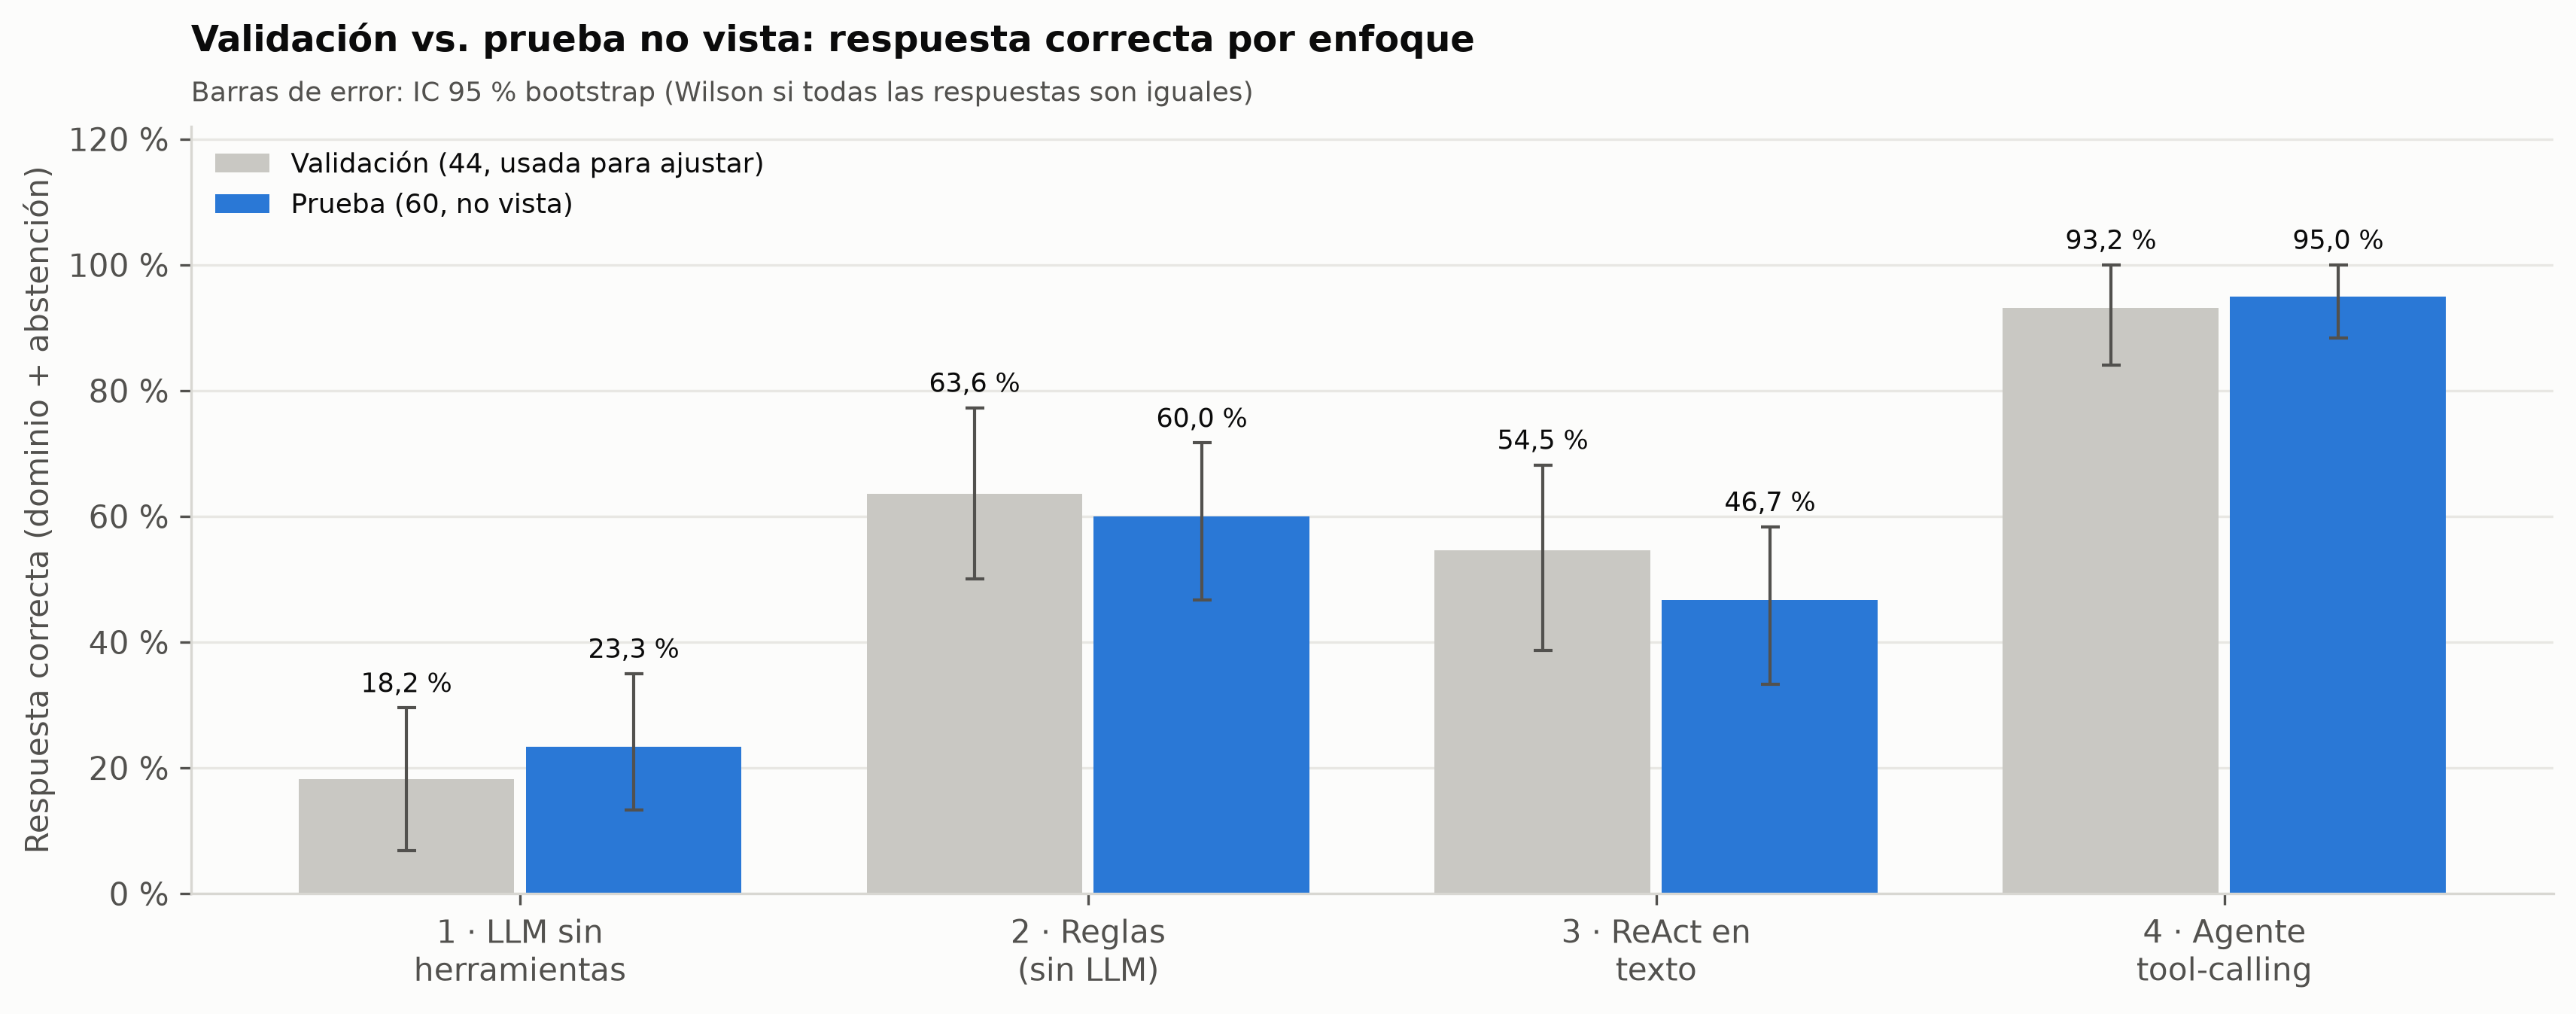

In [3]:
display(Image(filename=str(REP / "figures" / "02_validacion_vs_prueba.png")))

## 3.2 · Atribución: LLM frente a código determinista

,conjunto,version_prompt,responsable,etapa,valor
0,validacion,v2,LLM,Elige la combinación exacta de herramientas en el 1.er turno,0.8611
1,validacion,v2,LLM,Elige la combinación exacta de herramientas (todos los turnos),0.9444
2,validacion,v2,LLM,"Herramientas y argumentos exactos (año, país, ciudad, cifras)",0.8611
3,validacion,v2,LLM,Exactitud media de argumentos,0.9792
4,validacion,v2,LLM,Se abstiene solo (no llama herramientas) fuera de dominio,0.3750
5,validacion,v2,Código,Abstención final fuera de dominio (tras Pydantic + anclaje),1.0000
6,validacion,v2,Código,Falsa abstención en dominio (anclaje/validación demasiado estrictos),0.0000
7,validacion,v2,LLM,Fidelidad numérica del texto que redacta el LLM,0.7639
8,validacion,v2,Código,Fidelidad de la respuesta final (plantilla: por construcción),0.9722
9,validacion,v2,Sistema,Respuesta correcta (todas las preguntas),0.9318


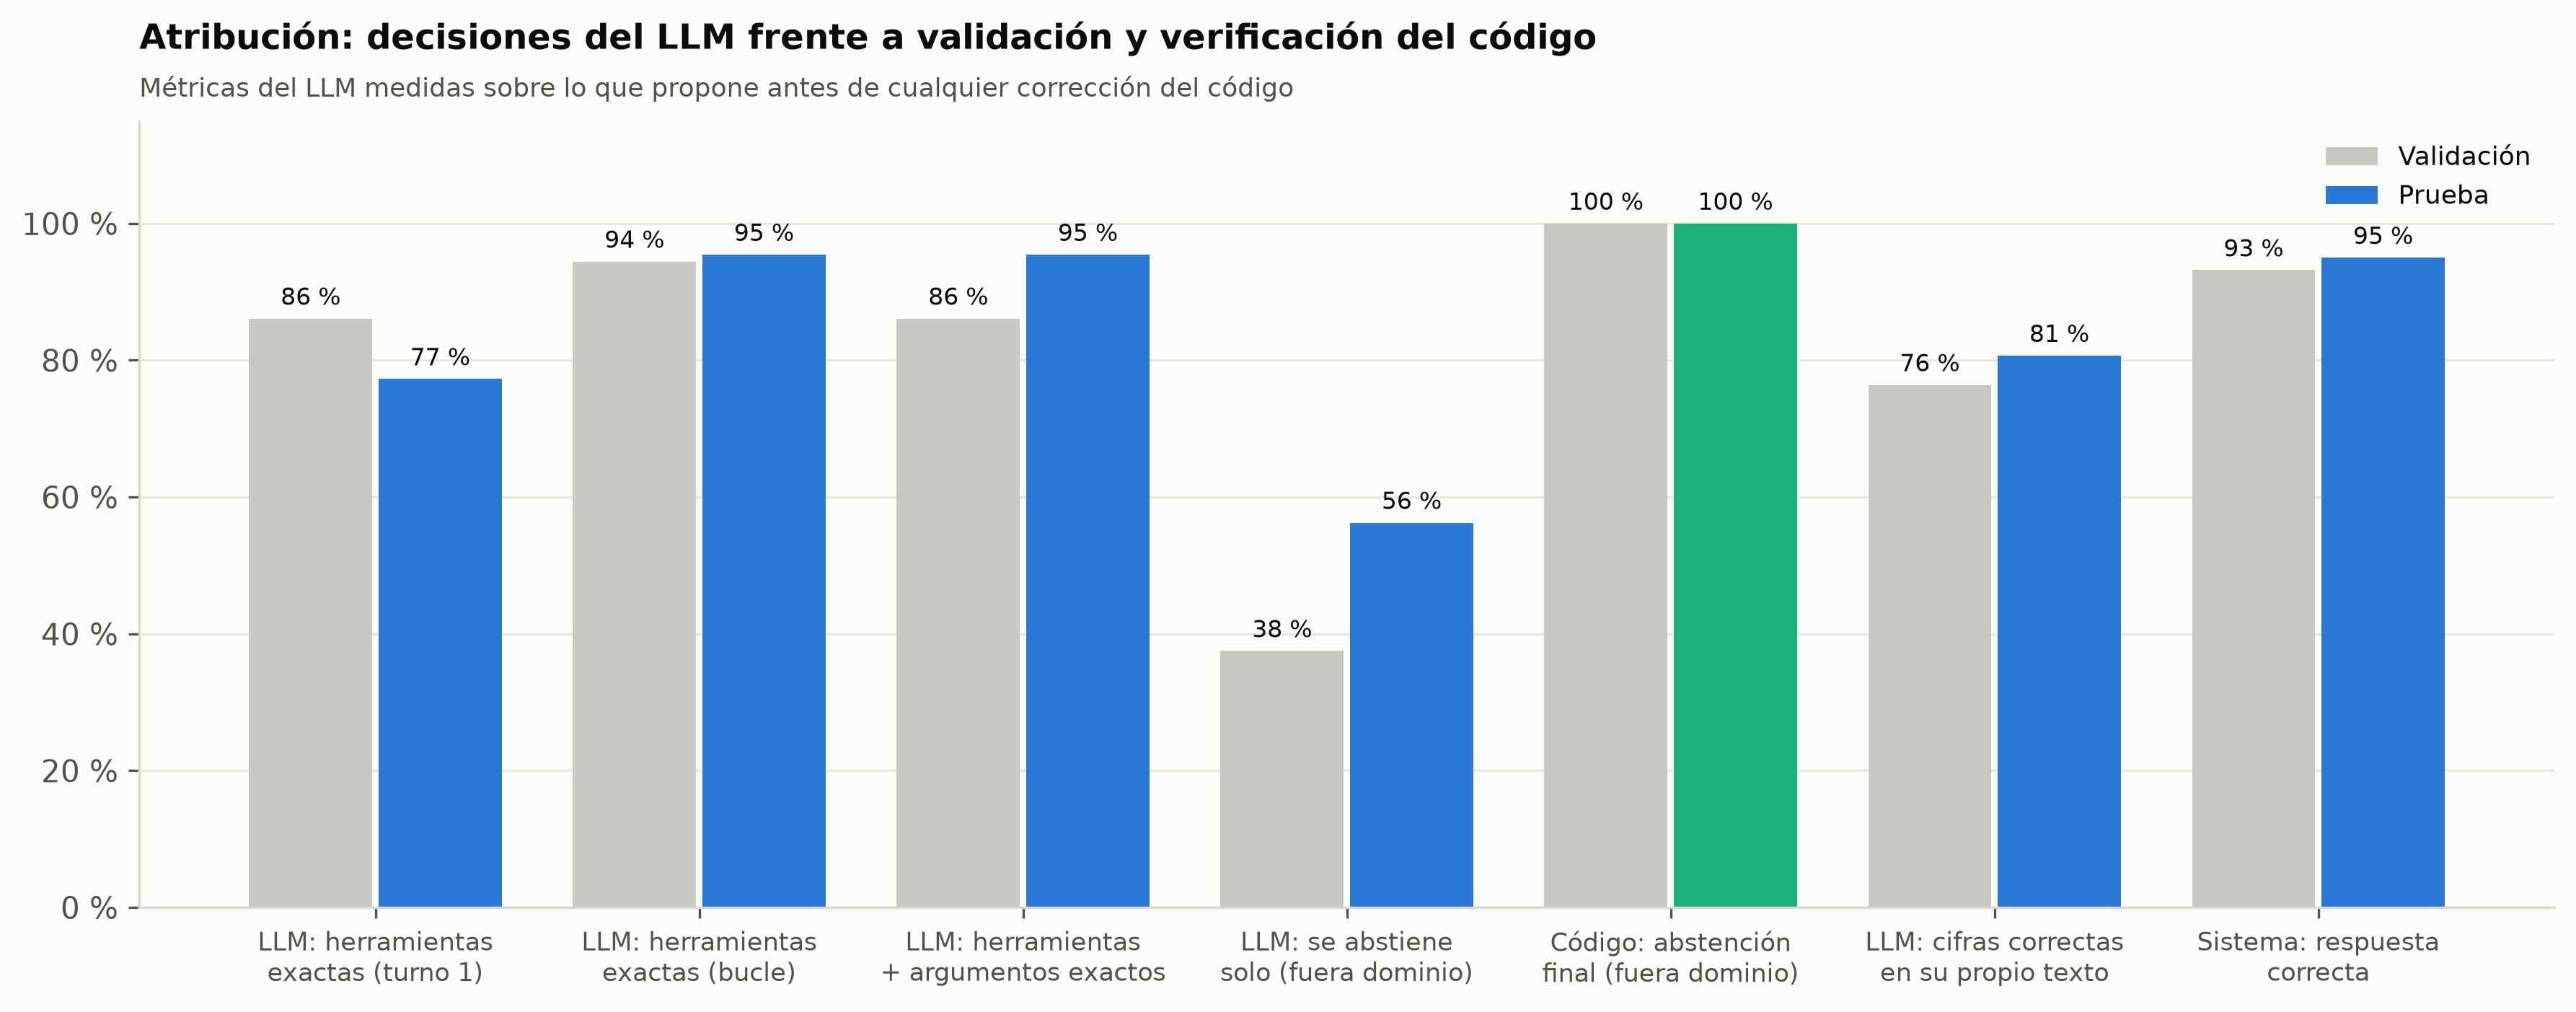

In [4]:
display(pd.read_csv(REP / "atribucion_llm_vs_codigo.csv"))
display(Image(filename=str(REP / "figures" / "03_atribucion_llm_vs_codigo.png")))

## 3.3 · Mejora de prompt medida en validación

,metrica,v1,v2,diferencia_v2_menos_v1
0,respuesta_correcta,0.8409,0.9318,0.0909
1,llm_seleccion_turno1,0.9167,0.8611,-0.0556
2,llm_seleccion_exacta,0.9167,0.9444,0.0277
3,llm_args_perfectos,0.7778,0.8611,0.0833
4,llm_se_abstuvo_ood,0.7500,0.3750,-0.3750
5,abstencion_correcta_ood,1.0000,1.0000,0.0000
6,falsa_abstencion_dominio,0.0000,0.0000,0.0000
7,fidelidad_texto_llm,0.8056,0.7639,-0.0417
8,pasos_llm_medios,1.8900,2.1100,0.2200
9,latencia_media_s,36.0500,49.2200,13.1700


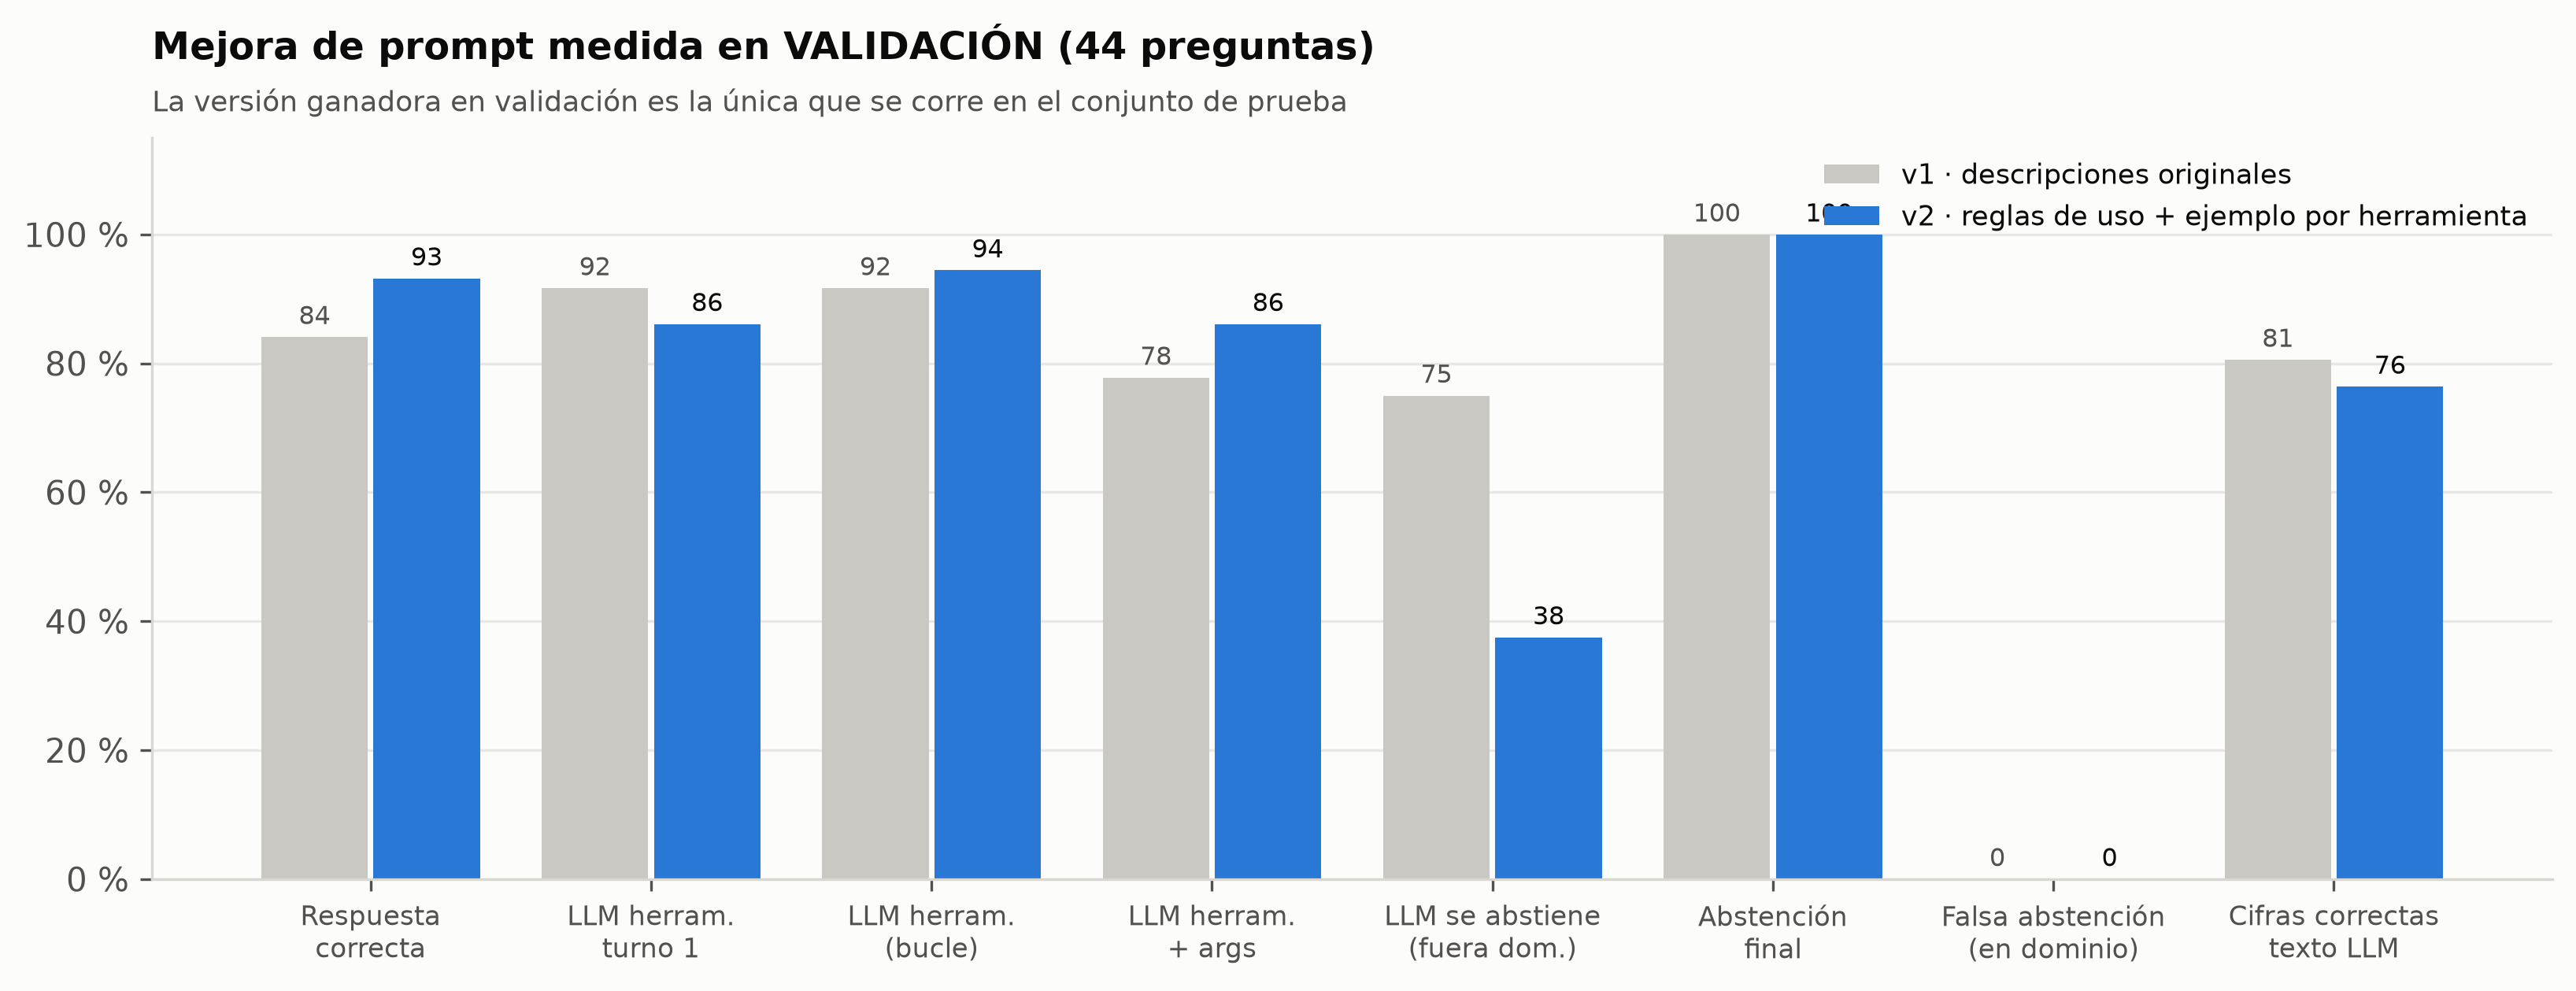

In [5]:
display(pd.read_csv(REP / "mejora_prompt_validacion.csv"))
display(Image(filename=str(REP / "figures" / "05_mejora_prompt_validacion.png")))

## 3.4 · Por tipo de pregunta, latencia y turnos del LLM

clave_enfoque,agente,enrutador_reglas,react_texto,zeroshot_sin_tools
categoria,,,,
calculo_variacion,0.8000,0.0000,0.0000,0.000
comparativa_paises,1.0000,1.0000,0.6000,0.000
cruce_clima_economia,1.0000,0.0000,0.0000,0.000
fuera_dominio,1.0000,1.0000,0.8125,0.875
simple_1hop,0.9286,0.7143,0.6429,0.000


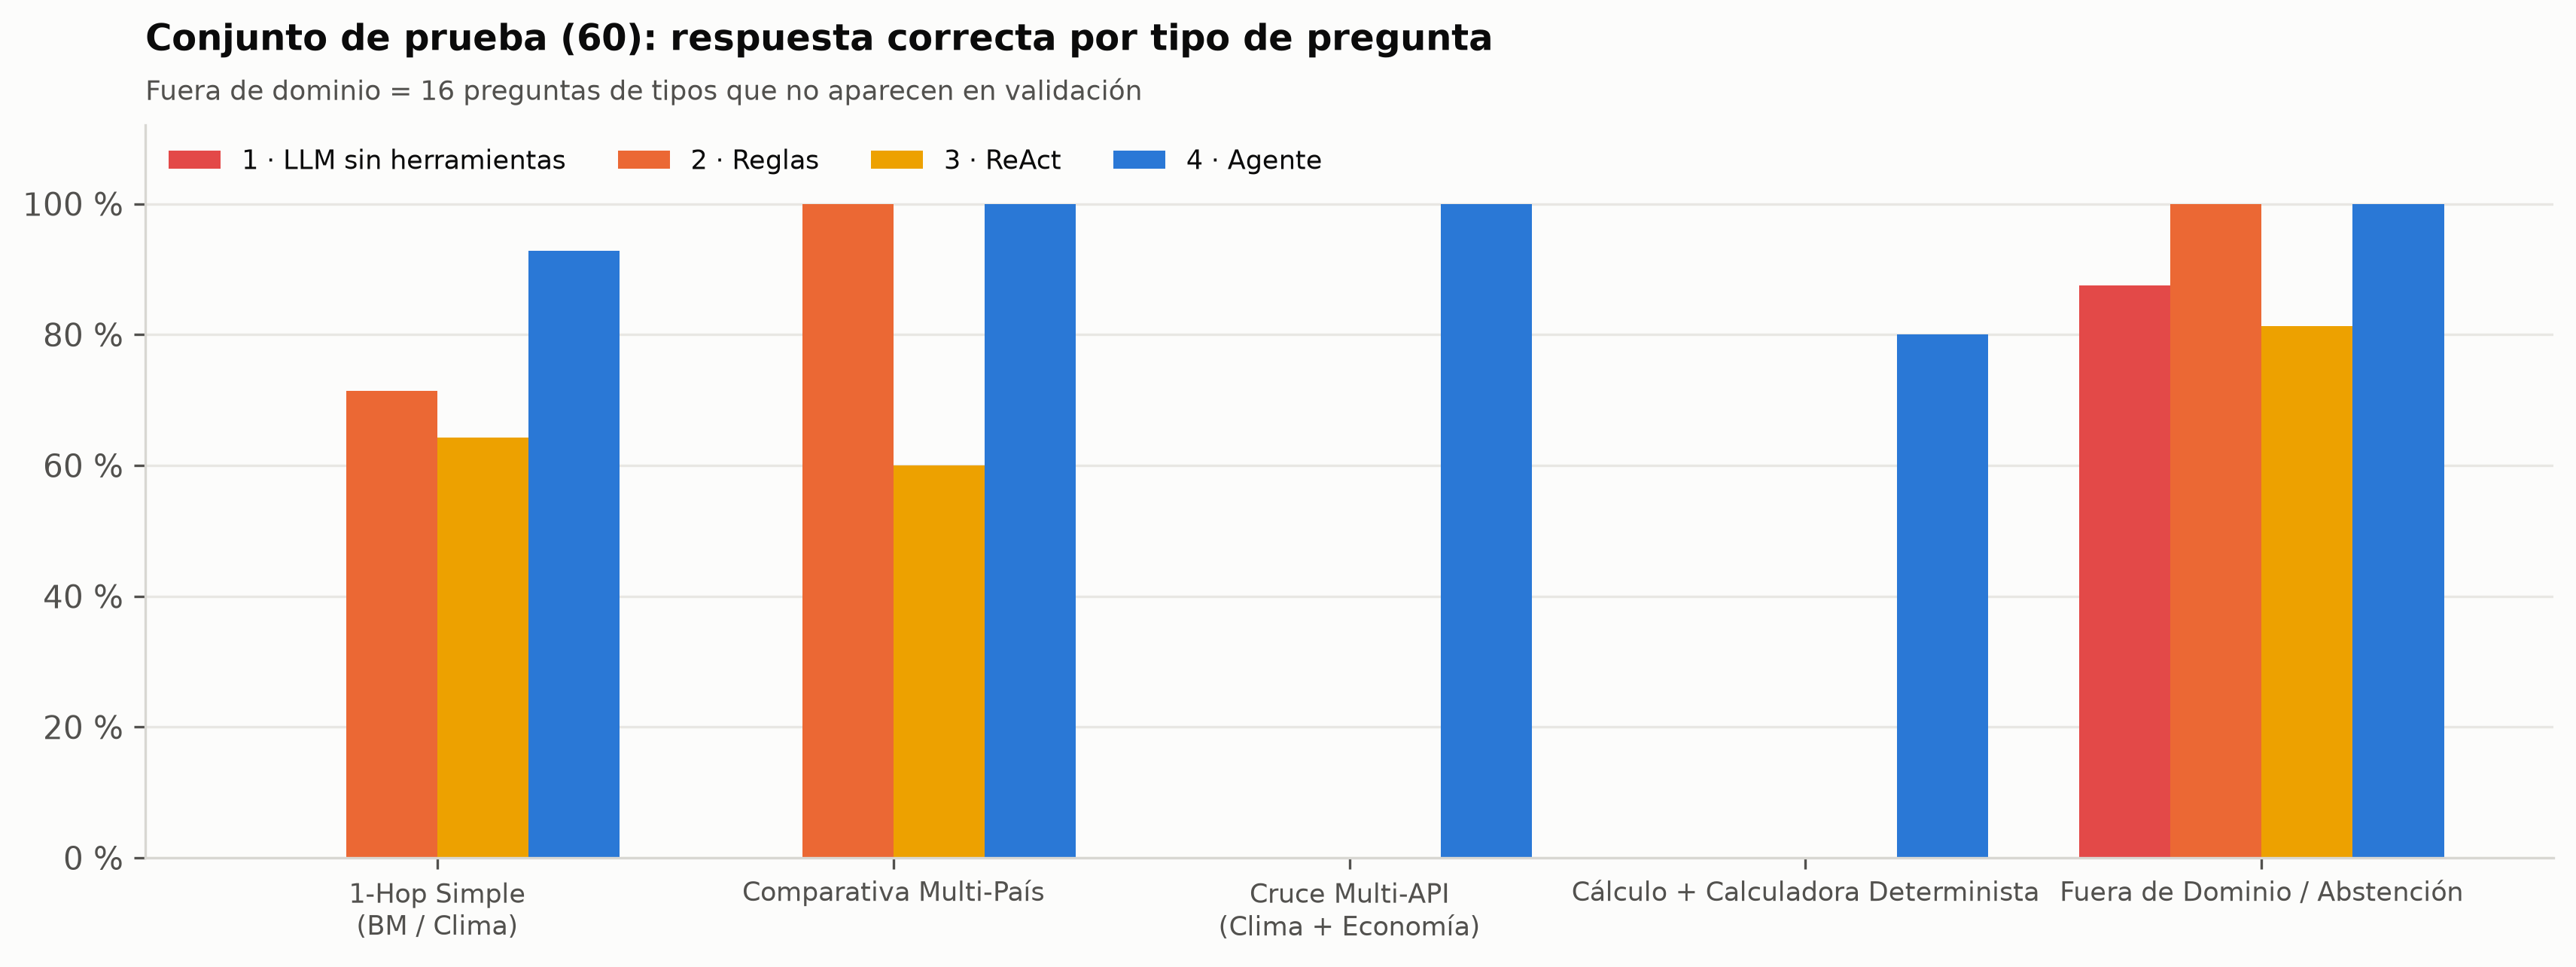

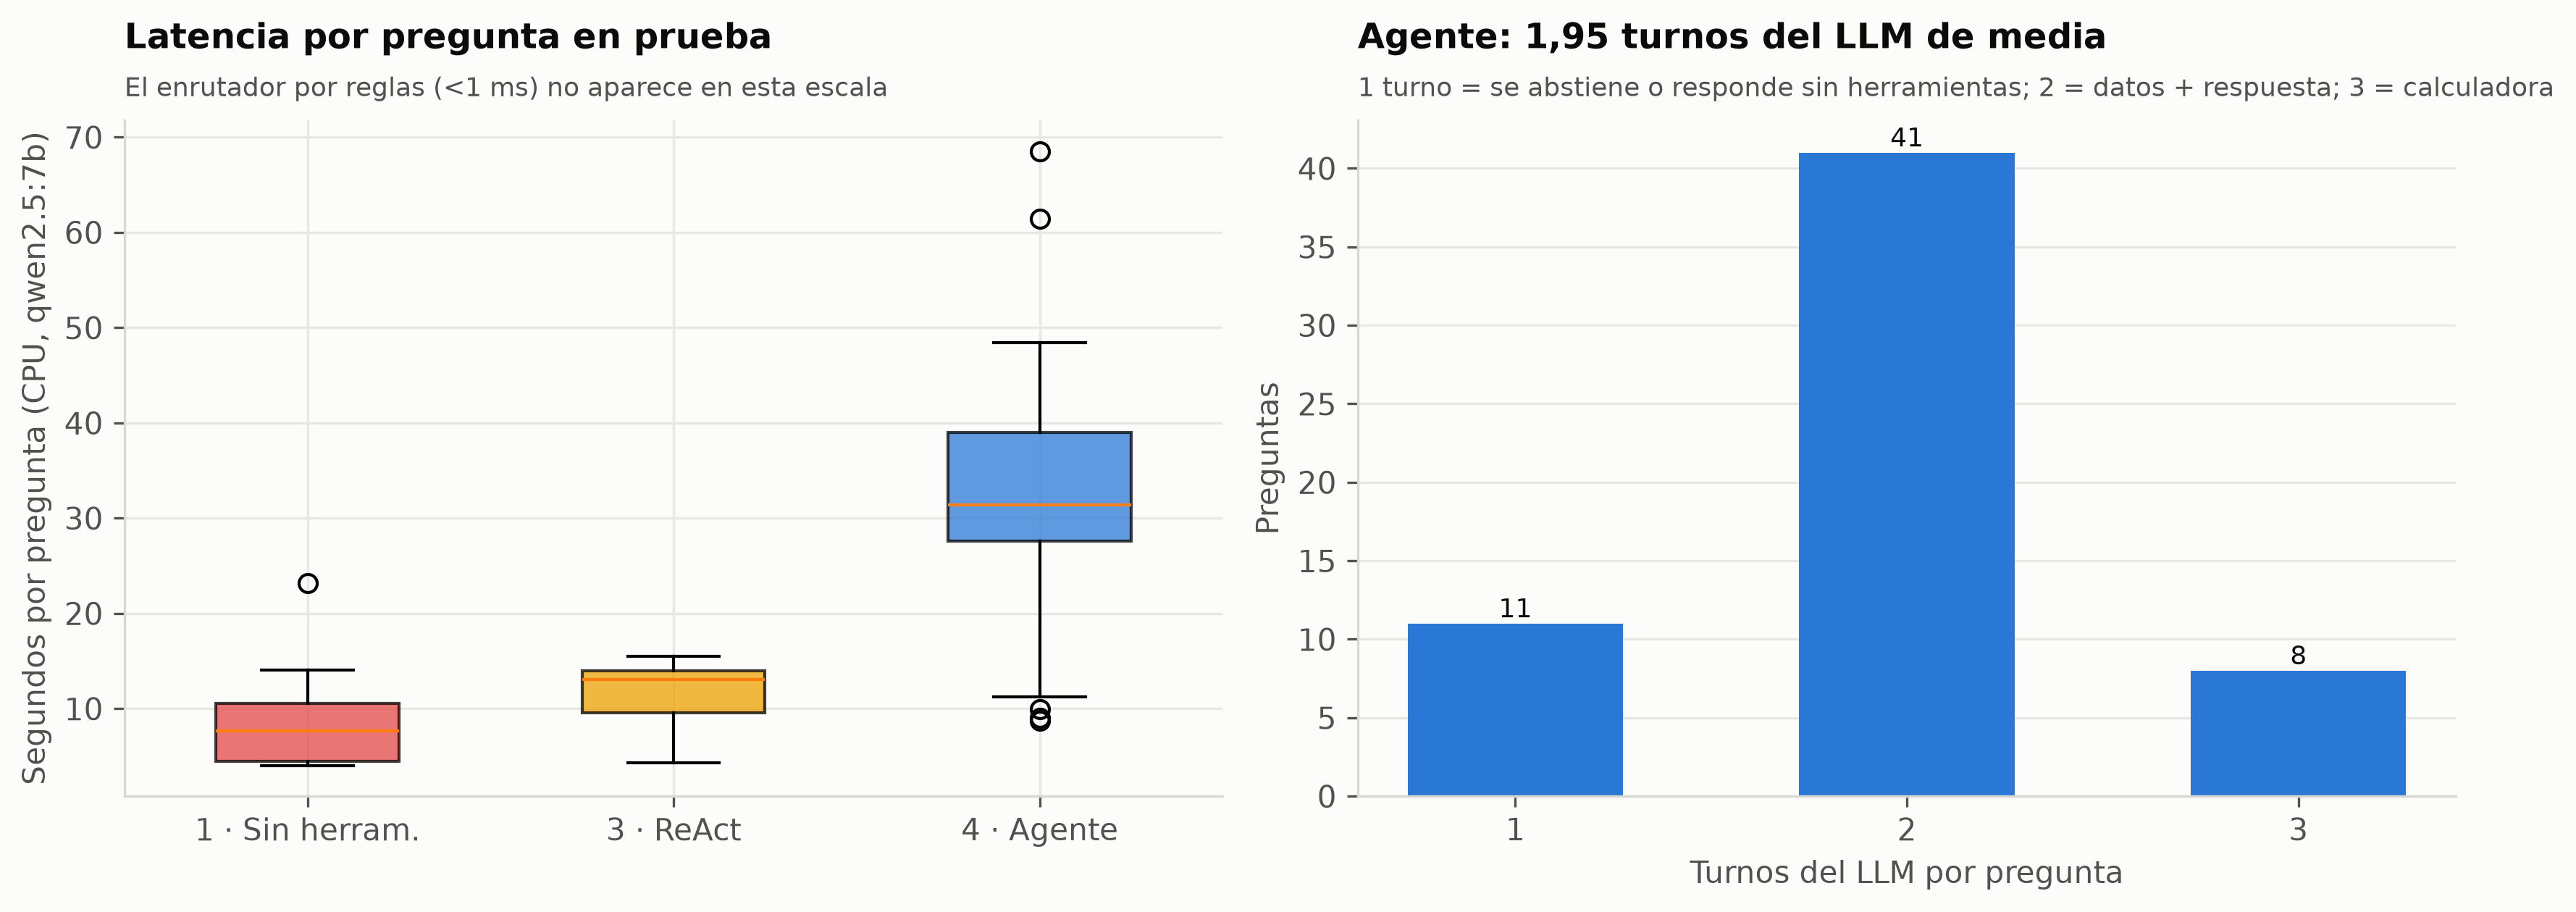

In [6]:
cat = pd.read_csv(REP / "desempeno_por_categoria.csv")
display(cat[cat["conjunto"] == "prueba"].pivot(index="categoria", columns="clave_enfoque", values="respuesta_correcta"))
for f in ("04_respuesta_correcta_por_categoria.png", "06_latencia_y_pasos_por_pregunta.png"):
    display(Image(filename=str(REP / "figures" / f)))

## 3.5 · Errores del agente en prueba

In [7]:
pd.read_csv(REP / "errores_agente_prueba.csv")

,id_pregunta,categoria,pregunta,herramientas_esperadas,herramientas_ejecutadas,respuesta_final
0,T06,simple_1hop,¿Qué porcentaje de los mexicanos usaba internet en 2020?,consultar_indicador_banco_mundial,ninguna,"ABSTENCIÓN: No puedo responder a esta consulta porque solicita datos, países..."
1,T36,calculo_variacion,Calcula la variación porcentual de la esperanza de vida de Bolivia de 2000 a...,"consultar_indicador_banco_mundial, calcular_correlacion_o_cambio",ninguna,"ABSTENCIÓN: No puedo responder a esta consulta porque solicita datos, países..."
2,T42,calculo_variacion,Variación porcentual de la energía renovable en Chile entre 2000 y 2020.,"consultar_indicador_banco_mundial, calcular_correlacion_o_cambio",ninguna,"ABSTENCIÓN: No puedo responder a esta consulta porque solicita datos, países..."


## 3.6 · Verificación de la verdad terreno contra las APIs en vivo

In [8]:
ver = pd.read_csv(REP / "verificacion_verdad_terreno_vivo.csv")
print(f"Llamadas verificadas: {len(ver)} · coinciden (<=0,5 %): {int(ver['coincide_0_5pct'].sum())}")
ver[~ver["coincide_0_5pct"]][["id_pregunta", "herramienta", "argumentos", "max_dif_relativa_pct", "error_vivo"]]

Llamadas verificadas: 98 · coinciden (<=0,5 %): 98


,id_pregunta,herramienta,argumentos,max_dif_relativa_pct,error_vivo


## 3.7 · API REST (FastAPI) con el rastro del agente

In [9]:
from agente import evaluacion
cliente = TestClient(app)
q = next(q["pregunta"] for q in evaluacion.cargar_conjunto("validacion") if q["id_pregunta"] == "V29")
r = cliente.post("/consultar", json={"pregunta": q, "enfoque": "tool_calling_nativo"}).json()
print(json.dumps({k: r[k] for k in ("respuesta_final", "n_pasos_llm", "llamadas_herramientas")}, ensure_ascii=False, indent=1))

{
 "respuesta_final": "Según el Banco Mundial (NY.GDP.PCAP.CD), PIB per cápita (USD actuales) en Ecuador (ECU) registró [2015: 5976.16 USD, 2016: 5917.64 USD, 2017: 6233.32 USD, 2018: 6303.92 USD, 2019: 6205.06 USD, 2020: 5463.65 USD, 2021: 6061.32 USD, 2022: 6515.59 USD, 2023: 6718.14 USD] (inicial 5976.16, final 6718.14, promedio 6154.98 USD). Cálculo determinista: al pasar de 5976.16 a 6718.14, el cambio absoluto es 741.98 y la variación porcentual exacta es 12.42 %.",
 "n_pasos_llm": 3,
 "llamadas_herramientas": [
  {
   "herramienta": "consultar_indicador_banco_mundial",
   "argumentos": {
    "codigo_pais": "ECU",
    "indicador": "pib_per_capita_usd",
    "anio_inicio": 2015,
    "anio_fin": 2023
   }
  },
  {
   "herramienta": "calcular_correlacion_o_cambio",
   "argumentos": {
    "valores_x": [
     5976.16,
     6718.14
    ],
    "valores_y": null,
    "operacion": "variacion_porcentual"
   }
  }
 ]
}
